# Model Evaluation Tool

In [34]:
%reset -f

In [35]:
import sys
sys.path.append('/NAS/PROJECTS/SIM_DOCTORANTS/e093728/rul-thesis/python_code/')
import pyrul
import pandas as pd
import tqdm

In [36]:
model_name = "DSCNN"
dataset_name = "femto"
data_root = "/NAS/PROJECTS/SIM_DOCTORANTS/e093728/rul-thesis/python_code/best_models/"+model_name+"/"+dataset_name+"/"
data_processed_paths = [data_root+"trial"+str(i)+"/preprocessed_data/"+model_name+"_paper_processed" for i in range(10)]
data_metrics_paths = [data_root+"trial"+str(i)+"/data_metrics/" for i in range(10)]
model_paths = [data_root+"trial"+str(i)+"/"+model_name for i in range(10)]
pred_paths = [data_root+"trial"+str(i)+"/preds/" for i in range(10)]

In [37]:
if dataset_name == "cmapss":
    data_test_load_path = "/NAS/PROJECTS/SIM_DOCTORANTS/e093728/rul-thesis/cmapss/test_FD001_fixed.txt"

elif dataset_name == "femto":
    if model_name in ["LR","SVR","MLS","TSBPDTW","DSCNN","RULRVE","DeepLSTM","DAST"]:
        data_test_load_path = "/NAS/PROJECTS/SIM_DOCTORANTS/e093728/rul-thesis/femto_alt/test_data.csv"
    elif model_name in ["GBT","GCUTCN"]:
        data_test_load_path = "/NAS/PROJECTS/SIM_DOCTORANTS/e093728/rul-thesis/femto/test_data.csv"
    else:
        raise ValueError("Model name not found.")

print("Path=", data_test_load_path)
tmp_plot_path = "/NAS/PROJECTS/SIM_DOCTORANTS/e093728/rul-thesis/python_code/tmp_plots/"

Path= /NAS/PROJECTS/SIM_DOCTORANTS/e093728/rul-thesis/femto_alt/test_data.csv


In [38]:
SEED = pyrul.utils.seed.get_seed(0)
pyrul.utils.seed.set_seed(SEED)

In [39]:
pyrul.utils.file.clear_tmp_plots("/NAS/PROJECTS/SIM_DOCTORANTS/e093728/rul-thesis/python_code/tmp_plots/")

In [27]:
mets = []
for i in tqdm.tqdm(range(10)):

    model = pyrul.models.rulrve.RULRVE_Model(
     DATASET_NAME="femto",
     R_EARLY = None,
     SEED = SEED
    )

    dl = pyrul.models.data.DataLoader(dataset="femto")
    
    dl.load_datasets(model=model, data=["train","val"], path=data_processed_paths[i])
    dl.load_data_metrics(model=model, path=data_metrics_paths[i])
    model.build_model()
    #model.fit_model()
    model.load_models(model_paths[i])
    dl.build_test_data(model, data_path=data_test_load_path)

    """evaluator = pyrul.evaluation.Evaluator(metrics=["scoring_"+dataset_name,
                                                    "rmse",
                                                    "mae",
                                                    "pmae",
                                                    "sstd",
                                                    "it",
                                                    "phase0_rmse",
                                                    "phase1_rmse",
                                                    "phase1_mae",
                                                    "phase1_pmae",
                                                    "phase0_sstd",
                                                    "phase1_sstd",
                                                    "pearsonr"])"""
    evaluator = pyrul.evaluation.Evaluator(metrics=["mae"])

    met = []
    for d in ["train","val","test","test_full","test_ind","test_full_ind"]:           
        df_metrics = evaluator.get_metrics(model, data=d, save_pred_path=pred_paths[i])
        met.append(df_metrics.mean())
    res = pd.concat(met)
    mets.append(res)

  0%|          | 0/10 [00:00<?, ?it/s]/NAS/PROJECTS/SIM_DOCTORANTS/e093728/envs/deepRUL/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 30 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


203/203 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
206/206 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
204/204 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 246ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━

 10%|█         | 1/10 [00:55<08:19, 55.48s/it]/NAS/PROJECTS/SIM_DOCTORANTS/e093728/envs/deepRUL/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 30 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
203/203 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
204/204 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
206/206 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 246ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━

 20%|██        | 2/10 [01:52<07:30, 56.31s/it]/NAS/PROJECTS/SIM_DOCTORANTS/e093728/envs/deepRUL/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 30 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


...

 80%|████████  | 8/10 [07:30<01:50, 55.39s/it]/NAS/PROJECTS/SIM_DOCTORANTS/e093728/envs/deepRUL/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 30 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
206/206 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
203/203 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 244ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━

 90%|█████████ | 9/10 [08:21<00:54, 54.22s/it]/NAS/PROJECTS/SIM_DOCTORANTS/e093728/envs/deepRUL/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 30 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
203/203 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
206/206 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
215/215 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 251ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━

100%|██████████| 10/10 [09:14<00:00, 55.41s/it]


In [8]:
#pd.DataFrame(mets).to_csv(model_name+"_"+dataset_name+"_metrics.csv")

## Plotting space

In [43]:
from pyrul.evaluation.metrics import rmse
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [40]:
i = 0


model = pyrul.models.dscnn.DSCNN_Model(
DATASET_NAME="femto",
R_EARLY = None,
SEED = SEED
)

dl = pyrul.models.data.DataLoader(dataset="femto")

dl.load_datasets(model=model, data=["train","val"], path=data_processed_paths[i])
dl.load_data_metrics(model=model, path=data_metrics_paths[i])
model.build_model()
#model.fit_model()
model.load_models(model_paths[i])
dl.build_test_data(model, data_path=data_test_load_path)

/NAS/PROJECTS/SIM_DOCTORANTS/e093728/envs/deepRUL/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 100 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [33]:
pyrul.models.viz.plot_pred(model, 
                            plot_indices=[10], #94,17,52
                            fold_indices=[-1],
                            model_indices=[-1], 
                            data_name="test_full", 
                            save_path=tmp_plot_path,
                            load_pred_path="/NAS/PROJECTS/SIM_DOCTORANTS/e093728/rul-thesis/python_code/best_models/DSCNN/femto/trial0/preds/test_full")

<Figure size 640x480 with 0 Axes>

In [41]:
X, y, lens = model._test_full_dataset["data"], model._test_full_dataset["labels"], model._test_full_dataset["lengths"]
#a, b = model.get_slices(idx=i, lengths=lens, is_test=True)
#X, y = X[a:b], y[a:b]

y_preds = [model.predict(X, k=k) for k in range(6)]

I0000 00:00:1761912648.448655 3053897 service.cc:145] XLA service 0x563ed6090ab0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1761912648.448756 3053897 service.cc:153]   StreamExecutor device (0): NVIDIA A30, Compute Capability 8.0
2025-10-31 13:10:48.479524: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


 44/427 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

I0000 00:00:1761912650.138197 3053897 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


427/427 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step
427/427 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step


In [44]:
np.std(y_preds, axis=0).mean()

4985.9297

<Axes: ylabel='Count'>

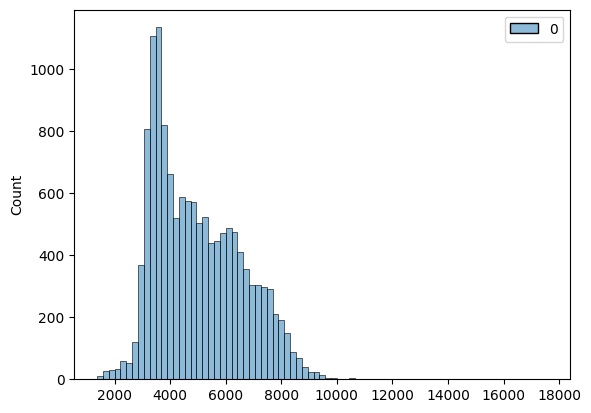

In [45]:
sns.histplot(np.std(y_preds, axis=0))

In [48]:
model._test_full_dataset["lengths"][0]

1802

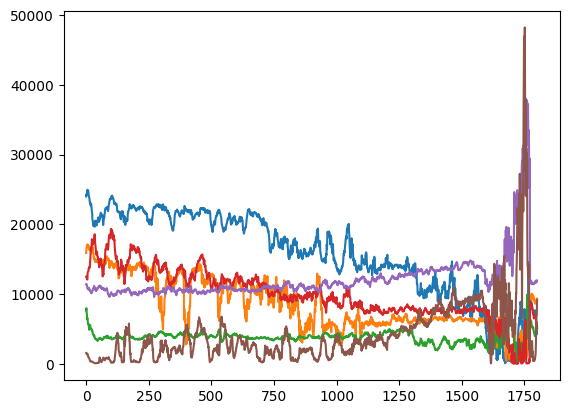

In [49]:
for y_pred in y_preds:
    plt.plot(y_pred[:1802])
#plt.plot(y)
plt.show()